<a href="https://colab.research.google.com/github/saitejagolla22/Thiranex-Internship/blob/main/WEEK_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:

# Cell 1: Import libraries and load dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

class_names = iris.target_names

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower classes:", list(class_names))
display(X.head())


Dataset loaded successfully!
Number of rows: 150
Number of features: 4
Flower classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
model = DecisionTreeClassifier(criterion="gini",max_depth=4,random_state=42)
model.fit(X_train, y_train)
print("Decision Tree model trained successfully!")


Training samples: 120
Testing samples: 30
Decision Tree model trained successfully!


In [13]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names=class_names))

Model Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



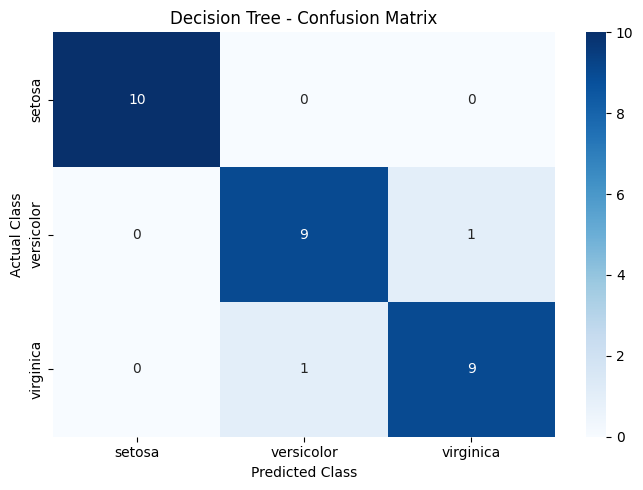

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

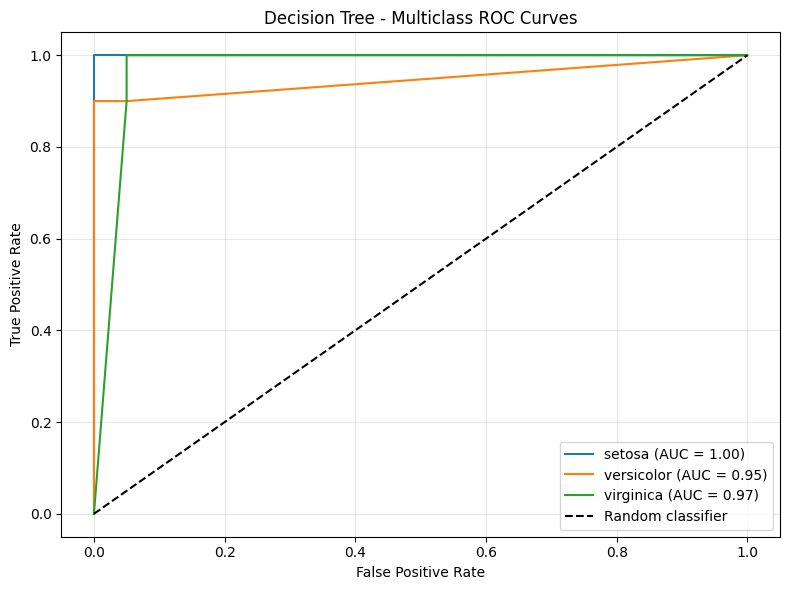

In [15]:
y_prob = model.predict_proba(X_test)
y_test_binary = label_binarize(y_test,classes=[0, 1, 2])
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(class_names):
    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr,tpr,label=f"{class_name} (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree - Multiclass ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


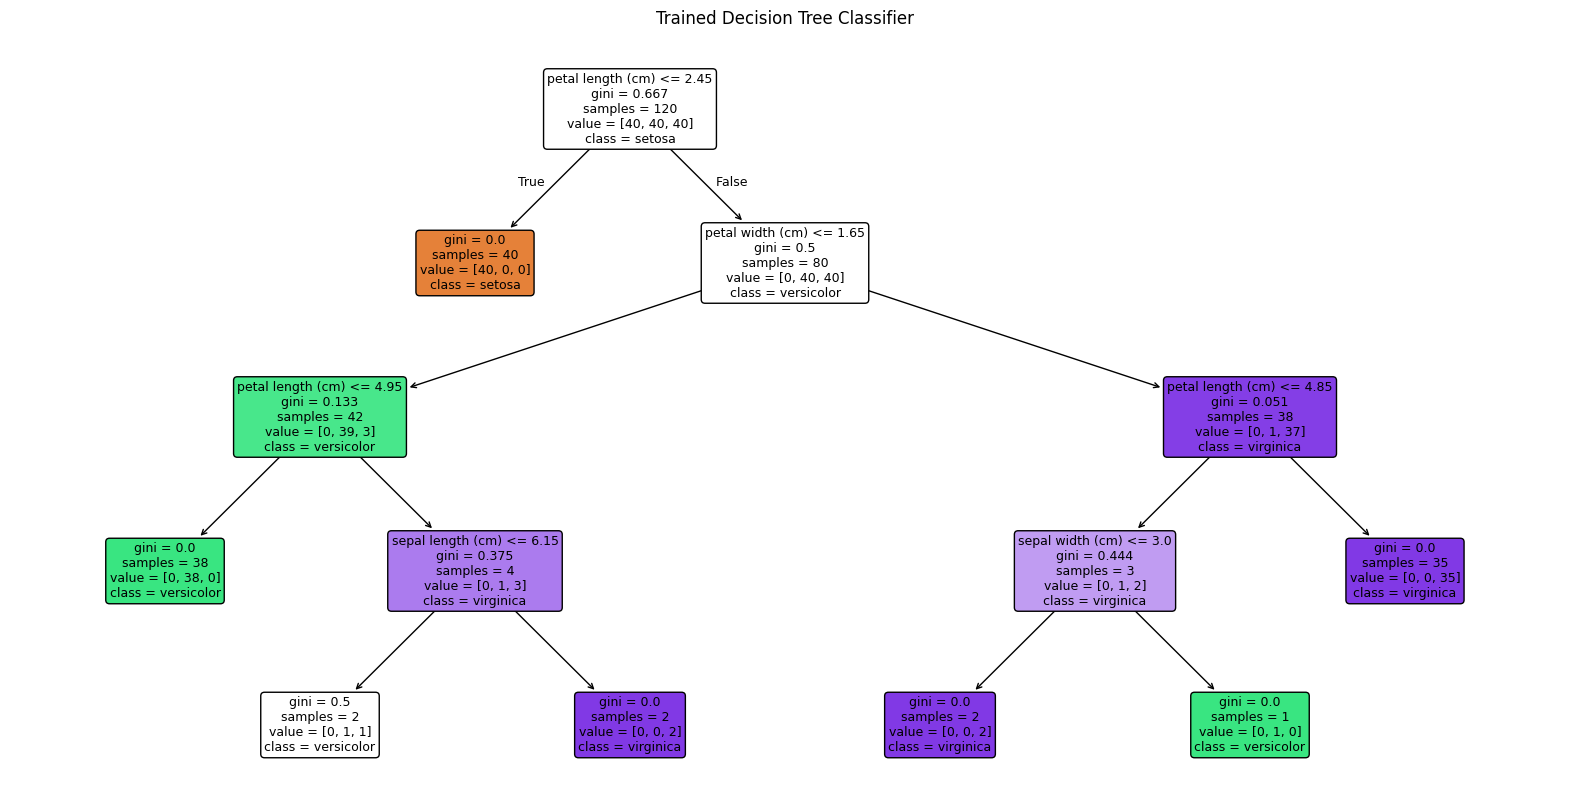

New flower measurements: [5.1, 3.5, 1.4, 0.2]
Predicted flower class: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [16]:
plt.figure(figsize=(20, 10))
plot_tree(model,feature_names=iris.feature_names,class_names=list(class_names),filled=True,rounded=True,fontsize=9)
plt.title("Trained Decision Tree Classifier")
plt.show()
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)
predicted_class = class_names[prediction[0]]
print("New flower measurements:", new_flower[0])
print("Predicted flower class:", predicted_class)